## Angewandtes Quantencomputing Laborpraktikum

### Praktikum 6: Logische Abfragen

In diesem Praktikum untersuchen wir zunächst, wie sich klassische logische Operationen wie AND, OR, XOR, etc. auf einem Quantencomputer umsetzen lassen. Dazu verwenden wir insbesondere das **X-Gatter**, das **CX-Gatter** (kontrolliertes NOT-Gatter) sowie das **CCX-Gatter** (Toffoli-Gatter).

Anschließend nutzen wir diese Bausteine, um komplexere logische Abfragen zu implementieren. Zum Abschluss formulieren wir die logischen Bedingungen eines vereinfachten Sudokus und lernen, wie sich solche Abfragen auf einem Quantencomputer realisieren lassen.

Zur Wiederholung fassen wir die wichtigsten Gatter noch einmal kurz zusammen.

#### CX- bzw. CNOT-Gatter

Das CX-Gatter wirkt auf zwei Qubits: ein Kontrollqubit und ein Zielqubit. Das Zielqubit wird genau dann mit einem X-Gatter invertiert, wenn das Kontrollqubit den Zustand $|1\rangle$ hat. Befindet sich das Kontrollqubit im Zustand $|0\rangle$, bleibt das Zielqubit unverändert.

Die Wirkung auf die Basiszustände lautet:

$$
|00\rangle \mapsto |00\rangle
\qquad
|01\rangle \mapsto |01\rangle
\qquad
|10\rangle \mapsto |11\rangle
\qquad
|11\rangle \mapsto |10\rangle
$$

#### CCX- bzw. Toffoli-Gatter

Das CCX-Gatter (Toffoli-Gatter) wirkt auf drei Qubits: zwei Kontrollqubits und ein Zielqubit. Das Zielqubit wird genau dann invertiert, wenn beide Kontrollqubits den Zustand $|1\rangle$ haben.

Für die logische Funktion sind insbesondere die folgenden Fälle relevant:

$$
|110\rangle \mapsto |111\rangle
$$

$$
|111\rangle \mapsto |110\rangle
$$
sonst bleibt der Quantenzustand unverändert:
$$
|000\rangle \mapsto |000\rangle
\qquad 
|100\rangle \mapsto |100\rangle
\qquad 
|010\rangle \mapsto |010\rangle
\qquad \ldots
$$


In allen anderen Fällen bleibt der Zustand unverändert.

Anschaulich entspricht das Toffoli-Gatter einer AND-Operation auf den Kontrollqubits, die das Zielqubit steuert.

In [18]:
import numpy as np
from qiskit import QuantumCircuit
from qc_lecture_tools.statevector import sv_state

### Aufgabe 1: Implementierung klassischer Logikgatter

**Ziel:** Realisieren Sie die klassischen Gatter **AND, XOR, OR, NAND** sowie eine **Gleichheitsüberprüfung (=)** mithilfe von Quantengattern.

Wir verwenden dazu drei Qubits:
- Qubit 0 und 1 dienen als **Input (A und B)**.
- Qubit 2 dient als **Output**, in dem das Ergebnis der Operation gespeichert wird.

Um die Gatter zu testen, verwenden wir einen Input-Zustand in Superposition, damit wir alle möglichen Input-Kombinationen gleichzeitig sehen können:
$$\ket{\Psi} = \frac{1}{2} (\ket{000} + \ket{010} + \ket{100} + \ket{110})$$
*Hinweis: Das dritte Qubit startet immer bei $\ket{0}$.*

**Wahrheitstabellen:** Die Logikgatter haben folgende Definition

<table>
<tr>
<td>

**AND**

|  A |  B |  A AND B |
|---------|---------|------------------|
|    0    |    0    |        0         |
|    0    |    1    |        0         |
|    1    |    0    |        0         |
|    1    |    1    |        1         |

</td>
<td>

**XOR**

|  A |  B |  A XOR B |
|---------|---------|------------------|
|    0    |    0    |        0         |
|    0    |    1    |        1         |
|    1    |    0    |        1         |
|    1    |    1    |        0         |

</td>
<td>

**OR**

|  A |  B |  A OR B  |
|---------|---------|------------------|
|    0    |    0    |        0         |
|    0    |    1    |        1         |
|    1    |    0    |        1         |
|    1    |    1    |        1         |

</td>
<td>

**NAND**

|  A |  B |  A NAND B|
|---------|---------|------------------|
|    0    |    0    |        1         |
|    0    |    1    |        1         |
|    1    |    0    |        1         |
|    1    |    1    |        0         |

</td>
<td>

**Gleichheit (=)**

|  A |  B |  A = B   |
|---------|---------|------------------|
|    0    |    0    |        1         |
|    0    |    1    |        0         |
|    1    |    0    |        0         |
|    1    |    1    |        1         |

</td>
</tr>
</table>

Zur Überprüfung können wir die Funktion `compose`. Damit können wir den Test-Zustand (die Superposition der Inputs) vor unser Logikgatter hängen.

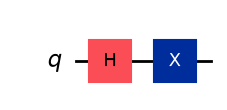

In [19]:
# Schaltkreis 1
quantum_circuit1 = QuantumCircuit(1)
quantum_circuit1.h(0)

# Schaltkreis 2
quantum_circuit2 = QuantumCircuit(1)
quantum_circuit2.x(0)

# Schaltkreis 1 + Schaltkreis 2
quantum_circuit3 = quantum_circuit1.compose(quantum_circuit2)
display(quantum_circuit3.draw("mpl"))

Um die Gatter Implementierung schnell zu überprüfen, nutzen wir eine gleichverteilte Superposition der ersten zwei Qubits: 

In [20]:
# Wir definieren uns zunächst den Superpositions Schaltkreis
qc_test = QuantumCircuit(3)
qc_test.h(0)
qc_test.h(1)
sv_state(qc_test, r"Input Zustand: ")

<IPython.core.display.Math object>

**Aufgabe 1.1:** AND-Gatter

In [21]:
# TODO Aufgabe 1.1

**Aufgabe 1.2:** XOR-Gatter

In [22]:
# TODO Aufgabe 1.2

**Aufgabe 1.3:** OR-Gatter

In [23]:
# TODO Aufgabe 1.3

**Aufgabe 1.4:** NAND-Gatter

In [24]:
# TODO Aufgabe 1.4

**Aufgabe 1.5:** Gleichheitsüberprüfung (=)

In [25]:
# TODO Aufgabe 1.5

### Aufgabe 2: Komplexere logische Abfragen

Nun verallgemeinern wir das Prinzip. Wir haben Daten-Qubits und wollen eine komplexe Bedingung prüfen, deren Ergebnis in einem zusätzlichen Qubit auch Ancilla Qubit genannt gespeichert wird.

**Beispiel:** Prüfen, ob in zwei Datenqubits genau ein Bit gesetzt ist (entspricht XOR).

In [26]:
qc_check = QuantumCircuit(3)
qc_check.cx(0, 2)
qc_check.cx(1, 2)

print("Zustand nach der Überprüfung (Qubit 2 ist Ergebnis):")
display(sv_state(qc_test.compose(qc_check)))

Zustand nach der Überprüfung (Qubit 2 ist Ergebnis):


<IPython.core.display.Math object>

**Aufgabe 2.1:** Implementieren Sie eine Abfrage für zwei Daten-Qubits ($q_0, q_1$), die nur dann eine $\ket{1}$ in das 3. Qubit schreibt, wenn beide Daten-Qubits im Zustand $\ket{0}$ sind.
(also $\ket{000} \rightarrow \ket{001}$, alle anderen Inputs führen zu Output $0$).

In [27]:
# TODO Aufgabe 2.1

**Aufgabe 2.2:** Wir haben drei Daten-Qubits ($q_0, q_1, q_2$). Implementieren Sie eine Schaltung, die ein Ancilla-Qubit ($q_3$) auf $\ket{1}$ setzt, wenn **beide** folgenden Bedingungen erfüllt sind:
1. Qubit 0 und Qubit 1 sind **nicht beide gleichzeitig** 1 
2. Qubit 1 und Qubit 2 sind **nicht beide gleichzeitig** 0 

Zustände für die beide Bedingungen erfüllt sind lauten: $001$, $010$, $011$, $101$

**Hinweis:** Sie werden noch zusätzliche Ancilla-Qubits verwenden müssen, um Zwischenergebnisse zu speichern, und diese dann mit einem weiteren Gatter kombinieren.

In [28]:
# TODO Aufgabe 2.2

### Aufgabe 3: Sudoku-Logik

Gegeben ist das folgende 2x2 Sudokus (Reihenfolge der Zahlen spielen keine Rolle)
 
| ? | 4 | 
|---|---|
| **2** | ? |

Eine valide Lösung ist gegeben, wenn jede Zahl nur einmal in den freien Plätzen des vorkommt. Mehre Zahlen oder Kästen vernachlässigen wir, da es sonst schnell zu viele Bits notwendig werden.

Wir stellen die Zahlen mit zwei Bits da:

- 1 &rarr; 00
- 2 &rarr; 01
- 3 &rarr; 10
- 4 &rarr; 11


Gesucht ist eine Quanten-Abfrage, die ein finales Ancilla-Qubit auf $\ket{1}$ setzt, wenn eine valide Lösung für die zwei unbekannten Felder vorliegt.

**Bedingungen für eine valide Lösung:**
1. Die unbekannten Zahlen dürfen keine 2 ($01$) und keine 4 ($11$) sein.
2. Die unbekannten Zahlen müssen untereinander verschieden sein.

Man sieht offensichtlich, dass die fehlenden Zahlen 1 und 3 sind. Die Abfrage sollte aber nicht lauten: ist der Bitstring $q_0q_1q_2q_3$ gleich 1000 oder 0010, da die Lösung ja sonst bekannt ist. 

**Aufgabe 3.1:**
Implementieren Sie eine Abfrage für zwei Qubits ($q_0, q_1$), die prüft, ob die kodierte Zahl **ungleich 2** ($01$) ist. Das Ergebnis soll in ein Ancilla-Qubit geschrieben werden. Erzeugen Sie für den Test eine gleichmäßige Überlagerung über alle vier möglichen Zustände in den ersten zwei Qubits und speichern Sie das Ergebnis in ein drittes Qubit. 

In [29]:
# TODO Aufgabe 3.1

**Aufgabe 3.2:**
Implementieren Sie eine Abfrage für zwei Qubits ($q_0, q_1$), die prüft, ob die kodierte Zahl **ungleich 4** ($11$) ist. Das Ergebnis soll in ein Ancilla-Qubit geschrieben werden. Gehen Sie genau so vor wie in Aufgabe 3.1.

In [30]:
# TODO Aufgabe 3.2

**Aufgabe 3.3: Mehrere Bedingungen kombinieren**
Prüfen Sie nun für die erste unbekannte Zahl (Qubits $q_0, q_1$), ob sie weder 2 (01) noch 4 (11) ist. Speichern Sie die Ergebnisse der Einzelprüfungen in Ancilla-Qubits und kombinieren Sie diese anschließend für die gemeinsame Abfrage in ein drittes Ancilla Qubit.
Erzeugen Sie wie zuvor eine Überlagerung der vier möglichen Zahlen (1-4) in ersten zwei Qubit und wenden Sie die Abfrage auf diese an.  

In [31]:
# TODO Aufgabe 3.3

**Aufgabe 3.4:**  Es fehlt noch die Abfrage, ob die beiden Zahlen unterschiedlich sind. Der Vergleich funktioniert hier am besten bitweise, also für die ersten zwei Bits und die zweiten Bits der Zahlen.

Das heißt, wir haben jetzt 4 Daten-Qubits: $\ket{q_0q_1 ~ q_2q_3}$.

Überlegen Sie sich, wie viele zusätzliche Ancilla-Qubits Sie für diese Abfrage benötigen, und implementieren Sie die Abfrage. Wenden Sie ihre Logische Abfrage wieder auf die gleichverteilte Superposition der Daten-Qubits and (Hadamard-Gatter auf alle 4 Daten-Qubits).  

Da wir nun viele Qubits und Zustände haben, wird es sehr unübersichtlich, alle Zustände auszugeben. Deshalb gibt es hier eine Hilfsfunktion, die alle Zustände ausgibt, wobei die ersten beiden Bits zu Zahl 1 gehören und die nächsten beiden Bits zu Zahl 2.

In [32]:
# Hilfsfunktion für die Ausgabe des Zustandsvektors
from qc_lecture_tools.statevector import sv_array
import numpy as np

def print_sudoku_states(quantum_circuit):
    statevector = sv_array(quantum_circuit)
    print("Gefundene Bitstrings in den Quantenzustand mit Amplituden ungleich Null:")
    for i, amplitude in enumerate(statevector):
        if np.abs(amplitude) > 1e-10:
            # Konvertierung von den Integerwerten in Bitstrings
            bitstr = format(i, f"0{quantum_circuit.num_qubits}b")
            print(f"{bitstr[:2]} {bitstr[2:4]} {bitstr[4:-1]} {bitstr[-1]}  ")

In [33]:
qc_34 = QuantumCircuit(4)

print_sudoku_states(qc_34)

Gefundene Bitstrings in den Quantenzustand mit Amplituden ungleich Null:
00 00  0  


**Bonusaufgabe: Vollständiger Sudoku-Check**
Wir haben nun 4 Datenqubits: $\ket{q_0 q_1}$ (Zahl 1) und $\ket{q_2 q_3}$ (Zahl 2).

Implementieren Sie den vollständigen Check:
- Zahl 1 ist nicht 2 oder 4.
- Zahl 2 ist nicht 2 oder 4.
- Zahl 1 $\neq$ Zahl 2.

Sie werden dabei zahlreiche Ancilla Qubits benötigen!
Ein mögliches Vorgehen ist, alles mit Gleichheit abzufragen, mit AND zu Verknüpfen und am Ende mit einer NOT Operation zu negieren. 

Nutzen Sie die Hilfsfunktion `print_sudoku_states`, um nur die Zustände anzuzeigen, bei denen das finale Ergebnis-Qubit auf $\ket{1}$ steht.

In [34]:
qc_sudoku = QuantumCircuit(12) 
# 4 Datenqubits (0-3)
# Rest Ancilla + 1 Ergebnisqubit (11)

# 1. Superposition der Datenqubits
qc_sudoku.h([0,1,2,3])

# 2. Logik-Implementierung
# TODO: Gesamte Sudoku-Abfrage hier implementieren

# 3. Auswertung
print_sudoku_states(qc_sudoku)

Gefundene Bitstrings in den Quantenzustand mit Amplituden ungleich Null:
00 00 0000000 0  
00 01 0000000 0  
00 10 0000000 0  
00 11 0000000 0  
01 00 0000000 0  
01 01 0000000 0  
01 10 0000000 0  
01 11 0000000 0  
10 00 0000000 0  
10 01 0000000 0  
10 10 0000000 0  
10 11 0000000 0  
11 00 0000000 0  
11 01 0000000 0  
11 10 0000000 0  
11 11 0000000 0  
